#Trabajo Principal

##**Con respecto a los filtros FIR de orden 60 (bueno) y de orden 10 (malo):**

**1. ¿Se aprecian diferencias en cuanto a la selección del orden correcto?
¿Cuáles?**

Sí, se aprecian diferencias muy claras. El filtro de orden 60 define correctamente la ventana y consigue una transición abrupta que respeta las frecuencias de interés. El de orden 10 no tiene muestras suficientes para definir bien la ventana, lo que provoca una transición mucho más ancha que deja "colarse" ruido en la banda de paso.  

**2. ¿Con cuál de los dos queda la señal más limpia?**

Con el filtro FIR de orden 60.

**3. Tras eliminar los trozos de señal filtrada que no sirven, comparando
las dos señales filtradas (Fig. 14), ¿dónde nos queda más señal útil?**

Con el filtro de orden 10. Al descartar las primeras $N-1$ muestras (donde $N$ es el orden del filtro), un filtro de menor orden destruye mucha menos cantidad de la señal original en los extremos.

**4. En relación a la pregunta anterior y pensando en conseguir el orden
más bajo posible para cualquier filtro, además de buscar una
ejecución del filtro más rápida y que consuma menos memoria, ¿hay
más ventajas por tener un orden bajo?**

Sí. Aparte de perder menos muestras iniciales (quedando más señal útil), un orden bajo implica mucha menos carga computacional. Se ejecutan menos operaciones matemáticas por muestra, el filtro es más rápido y se consume menos memoria en el procesador.  


##**Con respecto al filtro IIR Butterworth:**

**5. ¿Merece la pena pasar de un filtro FIR a un filtro IIR para realizar
el mismo filtrado (mismas especificaciones)? ¿Por qué?**

Definitivamente sí. Porque un filtro IIR como Butterworth consigue cumplir exactamente las mismas exigencias de atenuación y transición pero reduciendo el orden de 60 a solo 11. Esto agiliza el cálculo y preserva mucha más señal útil.


##**Con respecto al filtro IIR elíptico:**

**6. ¿Qué ventajas presenta el elíptico frente al Butterworth?, y ¿qué inconvenientes?**

Su gran ventaja es que ofrece la transición más abrupta posible, requiriendo un orden extremadamente bajo. Su inconveniente es que introduce rizado (distorsión) tanto en la banda de paso como en la de rechazo. Esto provoca pequeñas variaciones en la amplitud de la señal útil y permite que "sobrevivan" pequeños picos de ruido que no se logran atenuar del todo.

**7. ¿Y con respecto al orden del filtro?**

Es el filtro más eficiente en cuanto a tamaño: solo requiere orden 4 (frente a 11 de Butterworth y 60 de FIR).

##**Con respecto a la comparación de todos los filtros (Figs. 23 y 24):**

**8. ¿Qué filtro tiene la mayor selectividad?**

El filtro IIR elíptico. Sería el mejor para "cortar" como un bisturí una frecuencia de ruido que estuviera peligrosamente cerca de nuestra señal útil.

**9. ¿Se aprecian diferencias entre FIR y Butterworth en el centro y los extremos? ¿Con cuál te quedarías?**

En la parte central de la señal filtrada prácticamente no hay diferencias visuales; ambos limpian la señal de forma excelente. En los extremos, el FIR recorta muchísimas más muestras que el Butterworth. Para una aplicación real, me quedaría con el IIR Butterworth, ya que ofrece una calidad de filtrado excelente sin rizado, preservando mucha más señal y consumiendo menos recursos.

**10. ¿Qué diferencias hay entre el elíptico y el resto? ¿Consecuencias?**

El IIR elíptico altera ligeramente la amplitud de las ondas de baja frecuencia por el rizado en la banda de paso y mantiene leves irregularidades por el ruido residual. La consecuencia es que si la aplicación final requiriese medir con máxima precisión la amplitud de un pico (por ejemplo, en diagnóstico médico), el filtro elíptico introduciría un pequeño error de lectura inaceptable.

**Creación y análisis de la señal**

Para generar la señal original, utilizo el conjunto de valores de ejemplo [1, 4, 7, 9]. Al multiplicarlos por 1.5, obtengo cuatro frecuencias: **f1 = 1.5 Hz, f2 = 6.0 Hz, f3 = 10.5 Hz y f4 = 13.5 Hz**. A continuación, construyo la señal sumando estas cuatro sinusoides, con amplitud 1.0 para f1 y 0.4 para las demás, y visualizo su comportamiento en los dominios del tiempo y de la frecuencia mediante la Transformada Rápida de Fourier (FFT).

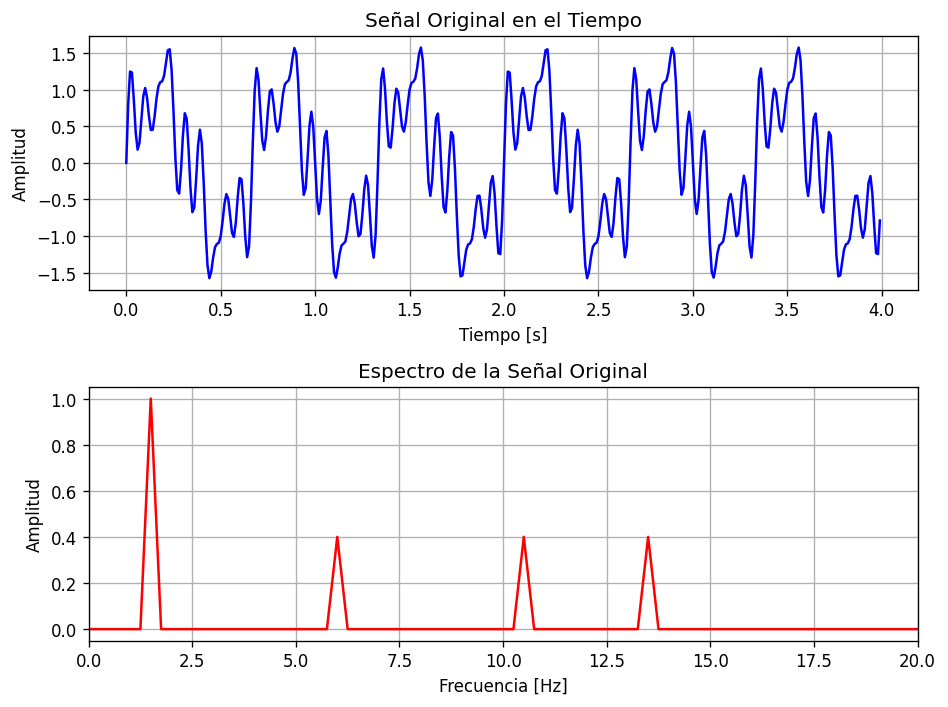

In [ ]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# 1. Parámetros de la señal
fs = 100.0 # [Hz]
n = 400 # 4 segundos (400 muestras a 100 Hz)
t = np.arange(n) / fs

# Frecuencias de ejemplo para el análisis [Hz]
f1 = 1.5
f2 = 6.0
f3 = 10.5
f4 = 13.5

# 3. Construcción de la señal
x = (1.0 * np.sin(2 * np.pi * f1 * t) +
     0.4 * np.sin(2 * np.pi * f2 * t) +
     0.4 * np.sin(2 * np.pi * f3 * t) +
     0.4 * np.sin(2 * np.pi * f4 * t))

# FFT de la señal
x_f = fft(x)[:n//2]
freqs = fftfreq(n, 1/fs)[:n//2]

# 4. Representación temporal y frecuencial
fig, axs = plt.subplots(2, 1, figsize=(8, 6), dpi=120)

axs[0].plot(t, x, 'b')
axs[0].set_title('Señal Original en el Tiempo')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].grid(True)

axs[1].plot(freqs, 2/n * np.abs(x_f), 'r')
axs[1].set_title('Espectro de la Señal Original')
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('Amplitud')
axs[1].set_xlim(0, 20)
axs[1].grid(True)

fig.tight_layout()
plt.show()

**Diseño y Aplicación del Filtro Principal**


Se establece un rizado máximo de 2.5 dB en la banda de paso y se permite rizado en la banda de rechazo. Por ello, selecciono un filtro IIR elíptico, que permite transiciones abruptas con un orden reducido. Configuro un rizado de 2.0 dB en la banda de paso (rpass=2.0), cumpliendo la restricción, para atenuar $f_3$ (10.5 Hz) y $f_4$ (13.5 Hz), preservando $f_1$ (1.5 Hz) y $f_2$ (6.0 Hz). Sitúo la frecuencia de corte entre 6.0 y 10.5 Hz.

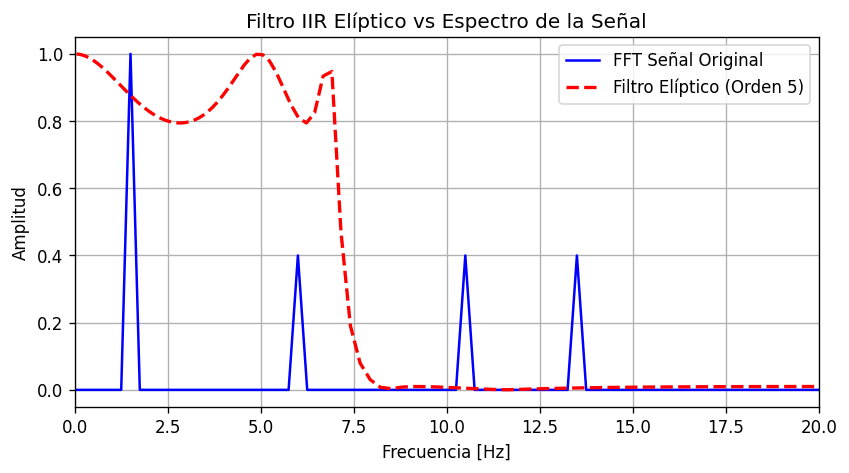

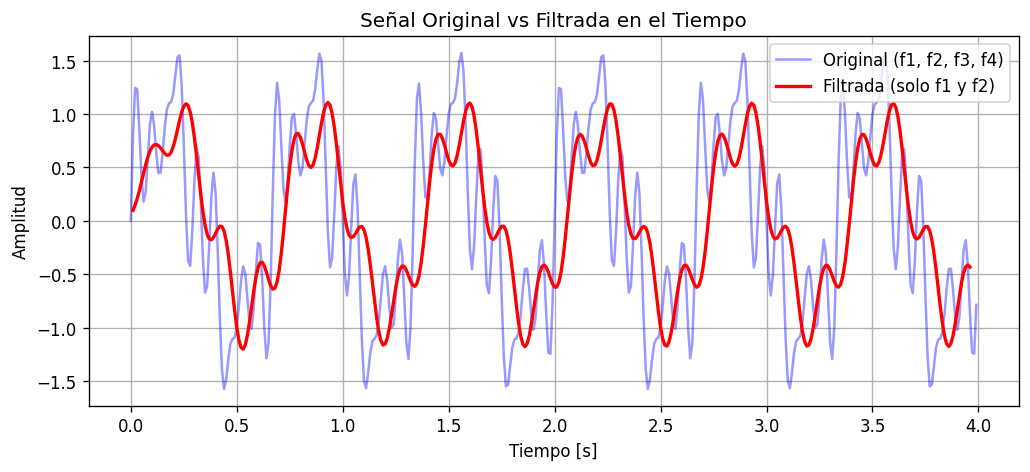

In [ ]:
# 5. Diseño del filtro IIR Elíptico (Paso Bajo)
f_nyq = fs / 2.0

# Quiero mantener hasta 6.0 Hz y eliminar a partir de 10.5 Hz
wp = 7.0 / f_nyq   # Fin de la banda de paso
ws = 9.0 / f_nyq   # Inicio de la banda de rechazo

# Especificaciones de diseño del filtro
gpass = 2.0  # Rizado tolerado en banda de paso (cumple <= 2.5 dB)
gstop = 40.0 # Atenuación en banda de rechazo

# Cálculo del orden
ord_ellip, Wn_ellip = sig.ellipord(wp, ws, gpass, gstop, analog=False, fs=fs)

# Generación del filtro para visualización
rpass = 2.0
rstop = 40.0
b_ellip, a_ellip = sig.ellip(ord_ellip, rpass, rstop, Wn_ellip, 'lowpass', analog=True, output='ba')
w_ellip, h_ellip = sig.freqs(b_ellip, a_ellip)

# 6. Visualización de la señal original vs respuesta del filtro
plt.figure(figsize=(8,4), dpi=120)
plt.plot(freqs, 2/n * np.abs(x_f), 'b-', label='FFT Señal Original')
plt.plot(w_ellip * f_nyq, np.abs(h_ellip), 'r--', linewidth=2, label=f'Filtro Elíptico (Orden {ord_ellip})')
plt.title('Filtro IIR Elíptico vs Espectro de la Señal')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud')
plt.xlim(0, 20)
plt.legend(loc='best')
plt.grid(True)
plt.show()

# 7. Filtrado de la señal y visualización en el tiempo
filtro_sos = sig.ellip(ord_ellip, rpass, rstop, Wn_ellip, 'lowpass', analog=False, output='sos')
x_filtrada = sig.sosfilt(filtro_sos, x)

# Ajustamos el retardo (elíptico de bajo orden suele tener muy poco delay)
delay_estimado = 0.03

plt.figure(figsize=(10,4), dpi=120)
plt.plot(t, x, 'b-', alpha=0.4, label='Original (f1, f2, f3, f4)')
plt.plot(t[ord_ellip-1:] - delay_estimado, x_filtrada[ord_ellip-1:], 'r-', linewidth=2, label='Filtrada (solo f1 y f2)')
plt.title('Señal Original vs Filtrada en el Tiempo')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.legend(loc='best')
plt.grid(True)
plt.show()

 Observando los resultados, pienso que el filtro se ha aplicado de manera totalmente correcta. La gráfica de frecuencias muestra cómo la respuesta del filtro abarca limpiamente $f_1$ y $f_2$, mientras que atenúa fuertemente a partir de 9 Hz (llevándose por delante $f_3$ y $f_4$). En el dominio del tiempo vemos cómo las oscilaciones nerviosas de alta frecuencia de la señal azul han sido extirpadas, dejando en la señal roja únicamente la combinación suave de las bajas frecuencias ($f_1$ y $f_2$). Gracias a la elección del filtro elíptico, esto se ha logrado con un coste computacional ínfimo.

#Trabajo Opcional

**Filtros Paso Alto y Paso Banda**

Para este apartado opcional, ya que no tengo restricciones impuestas, utilizaré un filtro IIR Butterworth tanto para el paso alto como para el paso banda. Lo elijo porque proporciona una respuesta plana y sin rizados, lo que me asegura un filtrado visualmente muy limpio de las sinusoides que quiero aislar.

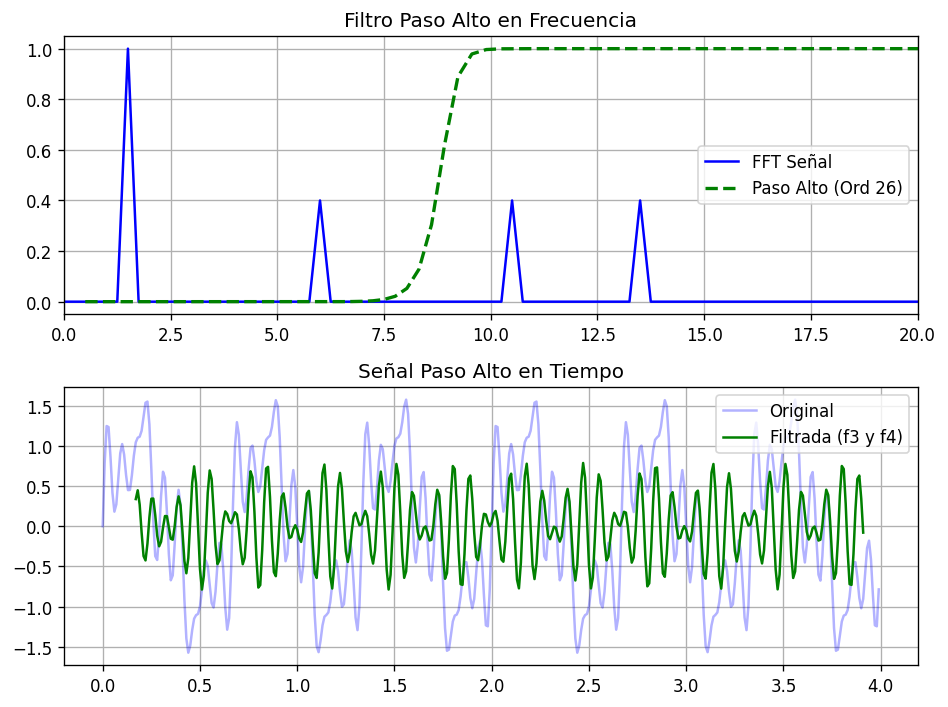

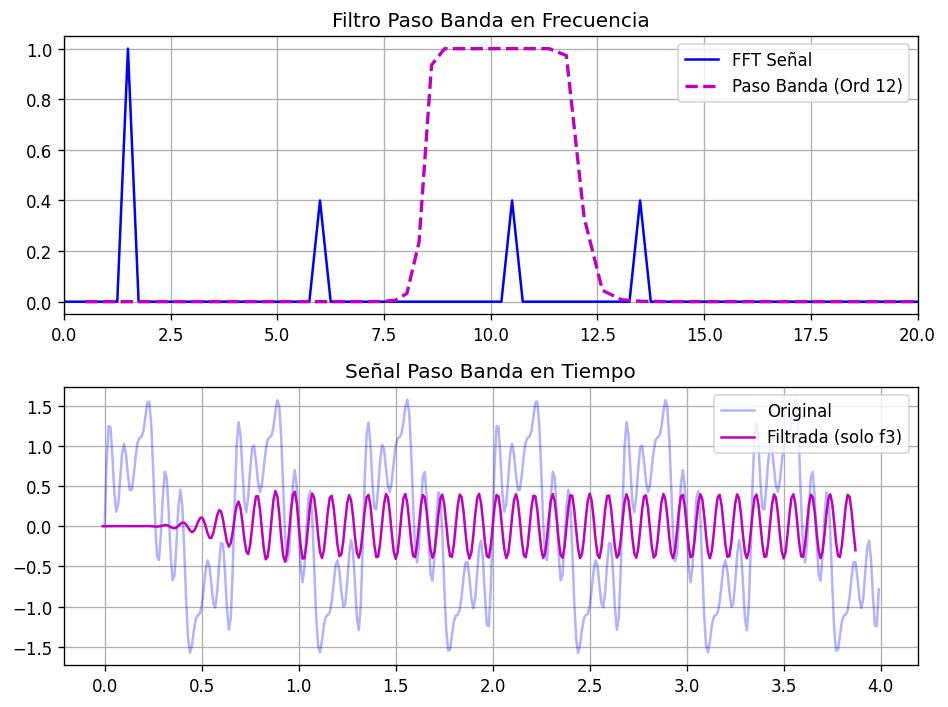

In [ ]:
# ==============================================================
# 1. FILTRO PASO ALTO (Deja pasar f3 y f4, elimina f1 y f2)
# ==============================================================
# Invertimos las bandas: queremos que deje pasar desde 9.0 Hz y rechace por debajo de 7.5 Hz
wp_high = 9.0 / f_nyq
ws_high = 7.5 / f_nyq

ord_hp, Wn_hp = sig.buttord(wp_high, ws_high, 3.0, 40.0, analog=False, fs=fs)
sos_hp = sig.butter(ord_hp, Wn_hp, btype='highpass', analog=False, output='sos')
b_hp, a_hp = sig.butter(ord_hp, Wn_hp, btype='highpass', analog=True, output='ba')

w_hp, h_hp = sig.freqs(b_hp, a_hp)
x_high = sig.sosfilt(sos_hp, x)

fig_hp, axs_hp = plt.subplots(2, 1, figsize=(8, 6), dpi=120)
axs_hp[0].plot(freqs, 2/n * np.abs(x_f), 'b-', label='FFT Señal')
axs_hp[0].plot(w_hp * f_nyq, np.abs(h_hp), 'g--', linewidth=2, label=f'Paso Alto (Ord {ord_hp})')
axs_hp[0].set_xlim(0, 20)
axs_hp[0].set_title('Filtro Paso Alto en Frecuencia')
axs_hp[0].legend()
axs_hp[0].grid(True)

axs_hp[1].plot(t, x, 'b-', alpha=0.3, label='Original')
axs_hp[1].plot(t[ord_hp-1:] - 0.08, x_high[ord_hp-1:], 'g-', label='Filtrada (f3 y f4)')
axs_hp[1].set_title('Señal Paso Alto en Tiempo')
axs_hp[1].legend()
axs_hp[1].grid(True)
fig_hp.tight_layout()

# ==============================================================
# 2. FILTRO PASO BANDA (Deja pasar solo f3 = 10.5 Hz)
# ==============================================================
# Debemos acorralar f3 (10.5Hz). Eliminamos <= 6.0Hz y >= 13.5Hz
wp_band = [8.5 / f_nyq, 12.0 / f_nyq] # Puntos 2 y 3 (sube antes de 10.5, baja antes de 13.5)
ws_band = [7.0 / f_nyq, 13.0 / f_nyq] # Puntos 1 y 4

ord_bp, Wn_bp = sig.buttord(wp_band, ws_band, 3.0, 40.0, analog=False, fs=fs)
sos_bp = sig.butter(ord_bp, Wn_bp, btype='bandpass', analog=False, output='sos')
b_bp, a_bp = sig.butter(ord_bp, Wn_bp, btype='bandpass', analog=True, output='ba')

w_bp, h_bp = sig.freqs(b_bp, a_bp)
x_band = sig.sosfilt(sos_bp, x)

fig_bp, axs_bp = plt.subplots(2, 1, figsize=(8, 6), dpi=120)
axs_bp[0].plot(freqs, 2/n * np.abs(x_f), 'b-', label='FFT Señal')
axs_bp[0].plot(w_bp * f_nyq, np.abs(h_bp), 'm--', linewidth=2, label=f'Paso Banda (Ord {ord_bp})')
axs_bp[0].set_xlim(0, 20)
axs_bp[0].set_title('Filtro Paso Banda en Frecuencia')
axs_bp[0].legend()
axs_bp[0].grid(True)

axs_bp[1].plot(t, x, 'b-', alpha=0.3, label='Original')
axs_bp[1].plot(t[ord_bp-1:] - 0.12, x_band[ord_bp-1:], 'm-', label='Filtrada (solo f3)')
axs_bp[1].set_title('Señal Paso Banda en Tiempo')
axs_bp[1].legend()
axs_bp[1].grid(True)
fig_bp.tight_layout()

plt.show()